# Demo hệ đa agent

Notebook chạy hệ thống trên các kịch bản tiêu biểu để thấy **mỗi loại câu hỏi đi một đường khác nhau** qua các agent,
kèm hai vòng phản hồi. Ánh xạ với sơ đồ trên bảng:

| Trên bảng | Trong hệ thống |
|---|---|
| ML/DL → Prediction/Classification | **Risk Agent** gọi mô hình XGBoost (dự đoán, SHAP, what-if) |
| KB ─RAG→ | **Knowledge Agent** truy vấn Knowledge Graph (GraphRAG) |
| Agent | **Supervisor** định tuyến, **Intake** thu thập hồ sơ |
| Hình tròn "+" | **Advisor** viết câu trả lời có trích dẫn, **Critic** kiểm duyệt trước khi trả |

Cần Ollama + Neo4j đang chạy và KG đã dựng (`kb/build_kg.ipynb`). Mỗi kịch bản mất khoảng 20–80 giây.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path(os.environ.get("PROJECT_DIR", Path.cwd())).resolve()
while not (ROOT / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent          # tìm thư mục src/Project
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
import warnings; warnings.filterwarnings("ignore")

import pandas as pd
from IPython.display import Markdown, display

from agents.graph import build_graph, load_scenarios, route_of, run_case
import nbstyle
nbstyle.install()           # bảng có màu cố định, đọc rõ ở cả giao diện sáng lẫn tối

APP = build_graph()
SCENARIOS = load_scenarios()


def show(state: dict) -> None:
    display(Markdown(f"**Đường đi:** {route_of(state)}  \n**Tổng thời gian:** {state['total_seconds']}s"))
    display(pd.DataFrame([{"agent": t["agent"], "quyết định": t["decision"], "giây": t["seconds"],
                           "lượt LLM": t["usage"]["calls"]} for t in state["trace"]]))
    display(Markdown("---\n" + state["answer"]))

## Cấu trúc đồ thị agent

Các cạnh nét đứt là **cạnh điều kiện** (agent quyết định tại thời điểm chạy). Ba cạnh quay lui tạo nên hành vi đa agent:
`Risk → Intake` (nhờ tìm thêm xét nghiệm), `Knowledge → Knowledge` (tự mở rộng truy vấn), `Critic → Advisor` (bác bản nháp).

In [2]:
display(Markdown("```mermaid\n" + APP.get_graph().draw_mermaid() + "\n```"))

```mermaid
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	supervisor(supervisor)
	intake(intake)
	risk(risk)
	knowledge(knowledge)
	advisor(advisor)
	critic(critic)
	finalize(finalize)
	__end__([<p>__end__</p>]):::last
	__start__ --> supervisor;
	advisor -.-> critic;
	advisor -.-> finalize;
	critic -.-> advisor;
	critic -.-> finalize;
	intake -.-> finalize;
	intake -.-> knowledge;
	intake -.-> risk;
	knowledge -.-> advisor;
	risk -.-> intake;
	risk -.-> knowledge;
	supervisor -.-> intake;
	supervisor -.-> knowledge;
	finalize --> __end__;
	knowledge -.-> knowledge;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc

```

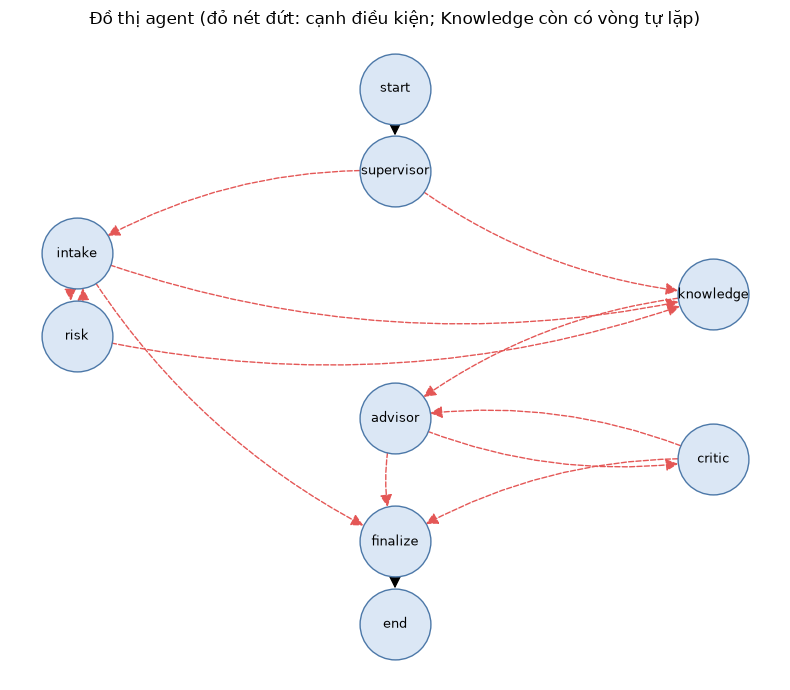

In [3]:
import matplotlib.pyplot as plt
import networkx as nx

g = APP.get_graph()
G = nx.DiGraph()
for edge in g.edges:
    G.add_edge(edge.source.strip("_"), edge.target.strip("_"), conditional=edge.conditional)
pos = {"start": (0, 4), "supervisor": (0, 3), "intake": (-1.5, 2), "risk": (-1.5, 1), "knowledge": (1.5, 1.5),
       "advisor": (0, 0), "critic": (1.5, -0.5), "finalize": (0, -1.5), "end": (0, -2.5)}
fig, ax = plt.subplots(figsize=(8, 7))
nx.draw_networkx_nodes(G, pos, node_size=2600, node_color="#dbe7f5", edgecolors="#4c78a8", ax=ax)
nx.draw_networkx_labels(G, pos, font_size=9, ax=ax)
solid = [(u, v) for u, v, d in G.edges(data=True) if not d["conditional"]]
dashed = [(u, v) for u, v, d in G.edges(data=True) if d["conditional"] and u != v]
nx.draw_networkx_edges(G, pos, edgelist=solid, arrows=True, arrowsize=18, node_size=2600, ax=ax)
nx.draw_networkx_edges(G, pos, edgelist=dashed, style="dashed", arrows=True, arrowsize=18, node_size=2600,
                       connectionstyle="arc3,rad=0.15", edge_color="#e45756", ax=ax)
ax.set_title("Đồ thị agent (đỏ nét đứt: cạnh điều kiện; Knowledge còn có vòng tự lặp)")
ax.axis("off"); fig.tight_layout()
fig.savefig("agents/figures/agent_graph.png", dpi=150); plt.show()

## 1. Câu hỏi kiến thức → bỏ qua Intake và Risk

Supervisor nhận ra đây là câu hỏi chung, không có thông tin cá nhân, nên chuyển thẳng sang Knowledge.

In [4]:
s = SCENARIOS["ask_symptoms"]
show(run_case(s["question"], s["form"], app=APP))

**Đường đi:** Supervisor → Knowledge → Advisor → Critic → Finalize  
**Tổng thời gian:** 29.3s

agent,quyết định,giây,lượt LLM
Supervisor,intent=ask → Knowledge,4.03,1
Knowledge,vòng 1: 10 bằng chứng → Advisor,11.37,4
Advisor,viết bản nháp,10.30,1
Critic,đạt → Finalize,3.58,1
Finalize,gắn 2 nguồn,0.00,0


---
Các triệu chứng phổ biến của bệnh tiểu đường tuýp 2 thường không xuất hiện ngay hoặc khá nhẹ ở giai đoạn đầu [9]. Các dấu hiệu điển hình bao gồm: nhìn mờ, mệt mỏi, ăn nhiều nhưng vẫn mau đói, uống nước nhiều nhưng vẫn khát và đi tiểu thường xuyên [9]. Một số trường hợp cũng có thể gặp các triệu chứng muộn của biến chứng như tê hai bàn tay hay hai bàn chân [10].

Tuy nhiên, đa phần người mắc bệnh không có đầy đủ các triệu chứng trên ngay từ đầu mà chỉ phát hiện khi có biến chứng hoặc qua xét nghiệm [10]. Vì các dấu hiệu này dễ bị nhầm lẫn với các vấn đề sức khỏe khác, bạn nên tham khảo ý kiến bác sĩ để được kiểm tra đường huyết và chẩn đoán chính xác. Hệ thống này chỉ cung cấp thông tin sàng lọc, không thay thế cho việc thăm khám y tế chuyên nghiệp.

**Nguồn (Nhà thuốc Long Châu):**
- [9][10] [Tiểu đường tuýp 2 là gì? Nguyên nhân, triệu chứng và cách điều trị](https://nhathuoclongchau.com.vn/benh/tieu-duong-tuyp-2.html)

> ⚠️ Kết quả chỉ mang tính tham khảo, được tạo tự động từ mô hình học máy và thông tin của Nhà thuốc Long Châu; không thay thế chẩn đoán của bác sĩ.

## 2. Thiếu dữ liệu → Intake hỏi lại người dùng

Không đủ giới tính / tăng huyết áp / bệnh tim nên không thể chạy mô hình; lượt kết thúc bằng câu hỏi bổ sung.

In [5]:
s = SCENARIOS["missing_fields"]
show(run_case(s["question"], s["form"], app=APP))

**Đường đi:** Supervisor → Intake → Finalize  
**Tổng thời gian:** 4.8s

agent,quyết định,giây,lượt LLM
Supervisor,intent=assess → Intake,3.05,1
Intake,thiếu dữ liệu → hỏi lại người dùng,1.72,1
Finalize,trả câu hỏi bổ sung cho người dùng,0.00,0


---
Để đánh giá nguy cơ, mình cần thêm: Giới tính, Tăng huyết áp, Bệnh tim. Nếu có, bạn cũng có thể gửi kết quả HbA1c và đường huyết để đánh giá chính xác hơn.

## 3. Chưa có xét nghiệm, rơi vào vùng xám → vòng `Risk → Intake → Risk`

Risk Agent dùng mô hình sàng lọc (không cần xét nghiệm); xác suất gần ngưỡng nên nhờ Intake tìm lại HbA1c/đường huyết
trong tin nhắn. Không có thì giữ kết quả và đề nghị người dùng đi xét nghiệm.

In [6]:
s = SCENARIOS["screening_grey"]
grey = run_case(s["question"], s["form"], app=APP)
show(grey)

**Đường đi:** Supervisor → Intake → Risk → Intake → Risk → Knowledge → Advisor → Critic → Finalize  
**Tổng thời gian:** 67.1s

agent,quyết định,giây,lượt LLM
Supervisor,intent=assess → Intake,3.52,1
Intake,hồ sơ hợp lệ → Risk,3.10,1
Risk,"8,6% trong vùng xám, thiếu xét nghiệm → nhờ Intake tìm thêm",7.07,4
Intake,"không có xét nghiệm → giữ mô hình screening, đề nghị bổ sung",12.10,2
Risk,"hồ sơ không đổi → giữ kết quả cũ, chuyển Knowledge",0.00,0
Knowledge,vòng 1: 10 bằng chứng → Advisor,20.89,3
Advisor,viết bản nháp,16.82,1
Critic,đạt → Finalize,3.53,1
Finalize,gắn 6 nguồn,0.00,0


---
Chào bạn, dựa trên thông tin bạn cung cấp, đây là kết quả sàng lọc sơ bộ:

**Đánh giá nguy cơ**
Mô hình tính toán xác suất mắc tiểu đường của bạn là **8,6%**. Tuy nhiên, chỉ số này nằm trong vùng "xám" vì nó gần với ngưỡng phân loại nguy cơ cao (**22,7%**). Yếu tố ảnh hưởng lớn nhất đến kết quả hiện tại là BMI của bạn (**29.0**), được xác định là một yếu tố nguy cơ đối với bệnh tiểu đường [9].

**Giải thích**
Mặc dù bạn không có tiền sử hút thuốc và tăng huyết áp (những yếu tố làm tăng nguy cơ theo tài liệu [5], [6]), nhưng chỉ số BMI 29 cho thấy tình trạng thừa cân/béo phì. Béo phì là một yếu tố nguy cơ chính đối với bệnh tiểu đường type 2 [10]. Ngoài ra, béo phì cũng có mối liên hệ mật thiết với tình trạng kháng insulin [2] và là nguyên nhân làm tăng nguy cơ mắc các bệnh tim mạch [8]. Lưu ý rằng kết quả này chưa bao gồm xét nghiệm HbA1c hoặc đường huyết nên độ chính xác còn hạn chế.

**Khuyến nghị**
Bạn đang ở mức nguy cơ cần lưu ý do chỉ số BMI cao. Để có chẩn đoán chính xác, bạn hãy gặp bác sĩ để thực hiện các xét nghiệm như đo đường huyết và HbA1c. Bác sĩ sẽ đánh giá toàn diện và đưa ra hướng dẫn phù hợp nhất cho sức khỏe của bạn.

**Lưu ý:** Bạn chưa cung cấp HbA1c hoặc đường huyết. Hãy làm xét nghiệm và gửi kết quả để mình đánh giá bằng mô hình đầy đủ, chính xác hơn.

**Nguồn (Nhà thuốc Long Châu):**
- [2] [Kháng insulin và béo phì có mối liên hệ gì? Đối tượng nào dễ mắc tiểu đường do béo phì?](https://nhathuoclongchau.com.vn/bai-viet/khang-insulin-va-beo-phi-co-moi-lien-he-gi-doi-tuong-nao-de-mac-tieu-duong-do-beo-phi.html)
- [5][10] [Đái tháo đường: Triệu chứng, nguyên nhân, chẩn đoán và điều trị](https://nhathuoclongchau.com.vn/benh/benh-tieu-duong-289.html)
- [6] [Những yếu tố nguy cơ đái tháo đường mà bạn nên biết](https://nhathuoclongchau.com.vn/bai-viet/dai-thao-duong-la-gi-nhung-yeu-to-nguy-co-dai-thao-duong-ma-ban-nen-biet.html)
- [8] [Bệnh tim mạch: Triệu chứng, nguyên nhân và cách điều trị](https://nhathuoclongchau.com.vn/benh/benh-tim-mach-599.html)
- [9] [Tiểu đường tuýp 2 là gì? Nguyên nhân, triệu chứng và cách điều trị](https://nhathuoclongchau.com.vn/benh/tieu-duong-tuyp-2.html)

> ⚠️ Kết quả chỉ mang tính tham khảo, được tạo tự động từ mô hình học máy và thông tin của Nhà thuốc Long Châu; không thay thế chẩn đoán của bác sĩ.

### 3b. Hội thoại nhiều lượt: người dùng gửi thêm kết quả xét nghiệm

Hồ sơ của lượt trước được giữ lại (`history_patient`); có đủ xét nghiệm nên Risk tự chuyển sang mô hình đầy đủ.

In [7]:
follow = run_case("Mình vừa xét nghiệm: HbA1c 6.0%, đường huyết 160 mg/dL.", history_patient=grey["patient"], app=APP)
show(follow)
print("Mô hình lượt 1:", grey["risk"]["model_used"], "→ lượt 2:", follow["risk"]["model_used"])

**Đường đi:** Supervisor → Intake → Risk → Knowledge → Advisor → Critic → Finalize  
**Tổng thời gian:** 60.0s

agent,quyết định,giây,lượt LLM
Supervisor,intent=assess → Intake,3.30,1
Intake,hồ sơ hợp lệ → Risk,3.22,1
Risk,"8,6% (mô hình full) → Knowledge",6.66,4
Knowledge,vòng 1: 10 bằng chứng → Advisor,17.22,2
Advisor,viết bản nháp,23.46,1
Critic,đạt → Finalize,6.12,1
Finalize,gắn 7 nguồn,0.00,0


---
Chào bạn, đây là kết quả phân tích dựa trên dữ liệu xét nghiệm của bạn:

**Đánh giá nguy cơ**
Mô hình tính toán xác suất mắc tiểu đường của bạn là **8,6%**, được xếp vào nhóm **nguy cơ thấp** so với ngưỡng 43,7% [8]. Tuy nhiên, chỉ số HbA1c của bạn là **6.0%** và đường huyết lúc đo là **160 mg/dL**.

**Giải thích**
Chỉ số HbA1c **6.0%** nằm trong khoảng **5.7–6.4%**, đây là ngưỡng chẩn đoán cho tình trạng tiền đái tháo đường hoặc nguy cơ đái tháo đường [3]. Về mặt chỉ số này, bạn chưa đạt ngưỡng chẩn đoán tiểu đường (> 6.5%) [2] nhưng cũng không còn ở mức bình thường (< 5.7%) [1].
Lưu ý quan trọng: Kết quả đường huyết **160 mg/dL** có thể được xếp vào nhóm nguy cơ cao nếu đây là kết quả đo **lúc đói**, vì ngưỡng chẩn đoán tiểu đường lúc đói là ≥ 126 mg/dL (≥ 7 mmol/L) [8]. Nếu đây là đường huyết sau ăn hoặc bất kỳ thời điểm nào, thì mức này chưa đạt ngưỡng ≥ 200 mg/dL để chẩn đoán tiểu đường [3].

**Khuyến nghị**
Do kết quả xét nghiệm cho thấy dấu hiệu tiền đái tháo đường và sự không rõ ràng về thời điểm đo đường huyết, bạn cần gặp bác sĩ để được giải thích chi tiết và thực hiện các xét nghiệm xác nhận chính thức. Bạn nên duy trì cân nặng hợp lý (BMI 29.0 đang ở mức cao) [5], tăng cường vận động và ăn uống lành mạnh với các thực phẩm như cà chua, hạnh nhân, rau xanh và ngũ cốc nguyên hạt để hỗ trợ kiểm soát đường huyết [9][10].

*Lưu ý: Hệ thống này chỉ hỗ trợ sàng lọc và không thay thế chẩn đoán của bác sĩ.*

**Nguồn (Nhà thuốc Long Châu):**
- [1][2][8] [Chỉ số HbA1c bình thường là bao nhiêu? Khi nào nên làm xét nghiệm HbA1c?](https://nhathuoclongchau.com.vn/bai-viet/chi-so-hb-a1c-binh-thuong-la-bao-nhieu-khi-nao-nen-lam-xet-nghiem-hb-a1-c.html)
- [3] [Đái tháo đường: Triệu chứng, nguyên nhân, chẩn đoán và điều trị](https://nhathuoclongchau.com.vn/benh/benh-tieu-duong-289.html)
- [5] [6 biến chứng bệnh tiểu đường thường gặp và cách phòng ngừa](https://nhathuoclongchau.com.vn/bai-viet/6-bien-chung-benh-tieu-duong-thuong-gap-va-cach-phong-ngua.html)
- [9][10] [Tiểu đường tuýp 2 là gì? Nguyên nhân, triệu chứng và cách điều trị](https://nhathuoclongchau.com.vn/benh/tieu-duong-tuyp-2.html)

> ⚠️ Kết quả chỉ mang tính tham khảo, được tạo tự động từ mô hình học máy và thông tin của Nhà thuốc Long Châu; không thay thế chẩn đoán của bác sĩ.

Mô hình lượt 1: screening → lượt 2: full


## 4. Mô hình và tri thức mâu thuẫn → Knowledge phát hiện, Advisor phải nêu

Trong dataset, nhóm HbA1c 6,5–7,0% chỉ có ~11,5% được gán nhãn mắc bệnh nên mô hình cho xác suất thấp. Nhưng theo
Long Châu, HbA1c ≥ 6,5% đã là ngưỡng chẩn đoán. Knowledge Agent đối chiếu chỉ số với ngưỡng trong KG; Critic bắt buộc
câu trả lời phải nêu điều này.

In [8]:
s = SCENARIOS["full_kg_conflict"]
conflict = run_case(s["question"], s["form"], app=APP)
show(conflict)

**Đường đi:** Supervisor → Intake → Risk → Knowledge → Advisor → Critic → Advisor → Critic → Finalize  
**Tổng thời gian:** 88.8s

agent,quyết định,giây,lượt LLM
Supervisor,intent=assess → Intake,2.90,1
Intake,hồ sơ hợp lệ → Risk,5.56,1
Risk,"10,9% (mô hình full) → Knowledge",6.35,4
Knowledge,vòng 1: 10 bằng chứng → Advisor,21.14,3
Advisor,viết bản nháp,23.44,1
Critic,bác bỏ (1 lỗi) → trả về Advisor,5.38,1
Advisor,viết lại theo góp ý Critic,18.91,1
Critic,còn 1 lỗi nhưng hết lượt sửa → Finalize,5.06,1
Finalize,gắn 3 nguồn,0.00,0


---
Chào bạn, đây là kết quả sàng lọc dựa trên thông tin bạn cung cấp. Lưu ý rằng hệ thống này chỉ hỗ trợ tham khảo và **không thay thế chẩn đoán của bác sĩ**.

**Đánh giá nguy cơ**
Mô hình ước tính xác suất mắc tiểu đường của bạn là **10,9%**, được xếp vào nhóm **nguy cơ thấp** so với ngưỡng 43,7%. Tuy nhiên, xét nghiệm HbA1c của bạn là **6.7%** đã **ĐẠT NGƯỠNG** chẩn đoán Đái tháo đường tuýp 2 (≥ 6.5%) theo tiêu chuẩn y khoa [2].

**Giải thích**
Mặc dù xác suất dự đoán từ mô hình khá thấp, chỉ số HbA1c 6.7% của bạn nằm trong ngưỡng > 6.5%, đây là một dấu hiệu quan trọng cho thấy lượng glucose trong máu có thể đang ở mức cao và chưa được kiểm soát tốt [2]. Về đường huyết 150 mg/dL (tương đương 8.33 mmol/L), cần lưu ý rằng hệ thống không rõ bạn đo lúc đói hay bất kỳ. Nếu đây là kết quả đo **lúc đói**, giá trị này đã **ĐẠT NGƯỠNG** chẩn đoán Đái tháo đường tuýp 2 (≥ 126 mg/dL hoặc ≥ 7 mmol/L) [2]. Ngược lại, nếu đo sau ăn, giá trị này chưa đạt ngưỡng chẩn đoán là ≥ 200 mg/dL [3]. Ngoài ra, bạn đang có yếu tố nguy cơ là tăng huyết áp [6].

**Khuyến nghị**
Vì chỉ số HbA1c của bạn đã vượt qua ngưỡng chẩn đoán, bạn **phải gặp bác sĩ ngay** để được xác nhận chính xác tình trạng bệnh thông qua xét nghiệm lâm sàng và tư vấn điều trị phù hợp. Không tự ý dùng thuốc hay thay đổi liều lượng. Bác sĩ sẽ đánh giá lại toàn diện dựa trên cả HbA1c, đường huyết lúc đói/2 giờ sau ăn và các triệu chứng lâm sàng để đưa ra kết luận cuối cùng.

**Nguồn (Nhà thuốc Long Châu):**
- [2] [Chỉ số HbA1c bình thường là bao nhiêu? Khi nào nên làm xét nghiệm HbA1c?](https://nhathuoclongchau.com.vn/bai-viet/chi-so-hb-a1c-binh-thuong-la-bao-nhieu-khi-nao-nen-lam-xet-nghiem-hb-a1-c.html)
- [3] [Đái tháo đường: Triệu chứng, nguyên nhân, chẩn đoán và điều trị](https://nhathuoclongchau.com.vn/benh/benh-tieu-duong-289.html)
- [6] [Chỉ số đường huyết tiền tiểu đường là bao nhiêu?](https://nhathuoclongchau.com.vn/bai-viet/chi-so-duong-huyet-tien-tieu-duong-la-bao-nhieu.html)

> ⚠️ Kết quả chỉ mang tính tham khảo, được tạo tự động từ mô hình học máy và thông tin của Nhà thuốc Long Châu; không thay thế chẩn đoán của bác sĩ.

In [9]:
pd.DataFrame(conflict["lab_checks"])[["test", "condition", "op", "value", "value_max", "unit",
                                    "patient_value_converted", "met"]]

test,condition,op,value,value_max,unit,patient_value_converted,met
HbA1c,HbA1c bình thường,range,4.0,6.0,%,6.70,✗
HbA1c,Đái tháo đường,>,6.5,—,%,6.70,✓
HbA1c,Tiền đái tháo đường hoặc nguy cơ đái tháo đường,range,5.7,6.4,%,6.70,✗
HbA1c,Hạ đường huyết,<,4.0,—,%,6.70,✗
HbA1c,Tiền tiểu đường,range,5.7,6.4,%,6.70,✗
HbA1c,Đái tháo đường tuýp 2,>=,6.5,—,%,6.70,✓
HbA1c,Đái tháo đường,>=,6.5,—,%,6.70,✓
HbA1c,Bình thường,<,5.7,—,%,6.70,✗
HbA1c,Mức bình thường,<,5.7,—,%,6.70,✗
Đường huyết bất kỳ,Đái tháo đường,>=,200.0,—,mg/dL,150.00,✗


In [10]:
pd.DataFrame(conflict["evidence"])[["n", "fact", "quote", "source_url"]]

n,fact,quote,source_url
1,HbA1c bình thường được chẩn đoán bằng HbA1c (4–6 %),"Ở người khỏe mạnh, HbA1c thường dao động trong khoảng 4 - 6% tổng lượng hemoglobin.",chi-so-hb-a1c-binh-thuong-la-bao-nhieu-khi-nao-nen-lam-xet-nghiem-hb-a1-c
2,Đái tháo đường được chẩn đoán bằng HbA1c (> 6.5 %),"Khi HbA1c trên 6,5%, điều đó cho thấy lượng glucose trong máu đang ở mức cao và không được kiểm soát tốt.",chi-so-hb-a1c-binh-thuong-la-bao-nhieu-khi-nao-nen-lam-xet-nghiem-hb-a1-c
3,Đái tháo đường được chẩn đoán bằng Đường huyết bất kỳ (≥ 200 mg/dL),"Đường huyết bất kỳ ≥ 200 mg/dL (11,1 mmol/L) kết hợp với các triệu chứng tăng đường huyết.",benh-tieu-duong-289
4,Đái tháo đường tuýp 2 được chẩn đoán bằng Đường huyết bất kỳ (≥ 200 mg/dL),Đường huyết bất kỳ: Lớn hơn hoặc bằng 200mg/dL (hay 11.1 mmol/L) và triệu chứng tăng đường huyết nghiêm trọng.,tieu-duong-tuyp-2
5,Cao huyết áp có yếu tố nguy cơ Tiền sử gia đình bạn mắc bệnh huyết áp cao,khi tiền sử gia đình bạn mắc bệnh huyết áp cao thì bạn cũng có khả năng cao bị bệnh này,9-nguyen-nhan-benh-cao-huyet-ap-ma-ban-can-biet-39118
6,Tiền tiểu đường có yếu tố nguy cơ Huyết áp cao (hoặc đang điều trị tăng huyết áp),huyết áp cao (hoặc đang điều trị tăng huyết áp),chi-so-duong-huyet-tien-tieu-duong-la-bao-nhieu
7,Bệnh cơ tim có yếu tố nguy cơ Béo phì,đặc biệt khi kèm tăng huyết áp hoặc béo phì,6-bien-chung-benh-tieu-duong-thuong-gap-va-cach-phong-ngua
8,Kháng insulin có yếu tố nguy cơ Béo phì,tình trạng kháng insulin và béo phì có mối liên hệ mật thiết với nhau,khang-insulin-va-beo-phi-co-moi-lien-he-gi-doi-tuong-nao-de-mac-tieu-duong-do-beo-phi
9,Tiền đái tháo đường hoặc nguy cơ đái tháo đường được chẩn đoán bằng HbA1c (5.7–6.4 %),"• HbA1c 5,7 đến 6,4%: Tiền đái tháo đường hoặc nguy cơ đái tháo đường.",benh-tieu-duong-289
10,Hạ đường huyết được chẩn đoán bằng HbA1c (< 4 %),"Ngược lại, HbA1c dưới 4% phản ánh tình trạng đường huyết thấp.",chi-so-hb-a1c-binh-thuong-la-bao-nhieu-khi-nao-nen-lam-xet-nghiem-hb-a1-c


## 5. Đòi kê đơn → không bao giờ có liều thuốc

KG được dựng **không** chứa mục "Liều dùng"; Critic có thêm luật chặn mọi con số kèm mg/viên/lần dùng.

In [11]:
s = SCENARIOS["prescription_request"]
show(run_case(s["question"], s["form"], app=APP))

**Đường đi:** Supervisor → Knowledge → Advisor → Critic → Finalize  
**Tổng thời gian:** 29.1s

agent,quyết định,giây,lượt LLM
Supervisor,intent=ask → Knowledge,2.74,1
Knowledge,vòng 1: 6 bằng chứng → Advisor,6.84,3
Advisor,viết bản nháp,16.40,1
Critic,đạt → Finalize,3.12,1
Finalize,gắn 5 nguồn,0.00,0


---
Chào bạn, tôi là Advisor Agent. Lưu ý quan trọng: Hệ thống này chỉ hỗ trợ sàng lọc thông tin và **không thay thế bác sĩ**. Tôi không thể kê đơn hay xác định liều lượng thuốc cụ thể cho bạn vì việc điều trị tiểu đường cần dựa trên tình trạng sức khỏe cá nhân (như chức năng thận, cân nặng, loại tiểu đường) do bác sĩ quyết định.

Theo tài liệu y khoa, Metformin là một lựa chọn phổ biến để kiểm soát đường huyết, nhưng có những chống chỉ định quan trọng bạn cần biết trước khi dùng [1][3][5]:
*   **Chống chỉ định** nếu bạn có bệnh gan/tim mạch nặng, suy hô hấp làm giảm oxy máu, hoặc nhiễm khuẩn nặng [1].
*   **Chống chỉ định** nếu bạn đang mang thai hoặc bị nhiễm acid chuyển hóa (bao gồm cả nhiễm acid ceton do đái tháo đường) [3][4].
*   **Chống chỉ định** nếu chức năng thận suy giảm (ví dụ: creatinine ≥ 1,5 mg/dl ở nam hoặc ≥ 1,4 mg/dl ở nữ) [5].

Ngoài ra, Metformin có thể gây các tác dụng phụ như buồn nôn, tiêu chảy, đầy bụng hoặc nổi mày đay [2].

**Khuyến nghị:**
Bạn cần gặp bác sĩ chuyên khoa để được thăm khám trực tiếp, kiểm tra chức năng thận và xác định liều lượng Metformin phù hợp nhất với cơ địa của bạn. Tuyệt đối không tự ý mua thuốc hoặc điều chỉnh liều mà chưa có chỉ định y tế.

**Nguồn (Nhà thuốc Long Châu):**
- [1][2][3][4][5] [Thuốc Metformin Stella điều trị đái tháo đường típ 2](https://nhathuoclongchau.com.vn/thuoc/metformin-1000mg-stella-6x10-30260.html)

> ⚠️ Kết quả chỉ mang tính tham khảo, được tạo tự động từ mô hình học máy và thông tin của Nhà thuốc Long Châu; không thay thế chẩn đoán của bác sĩ.